In [21]:
import numpy as np
import matplotlib.pyplot as plt
import time
from dataclasses import dataclass

np.random.seed(42)

@dataclass
class Params:
    S0: float = 100.0
    K: float = 100.0
    T: float = 1.0
    r: float = 0.05
    sigma: float = 0.5
    N: int = 300    # number of exercise dates
    M: int = 1 # number of processes (1 = standard, >1 = Asian-style)
    L: int =  1  # exercise rights
    delta: int = 0    # refractory period between exercises (0 = next step allowed)
    
    @property
    def dt(self): return self.T / self.N
    
    @property
    def df(self): return np.exp(-self.r * self.dt)

params = Params()
print(f"American Put: S0={params.S0}, K={params.K}, T={params.T}, r={params.r}, σ={params.sigma}, N={params.N}, M={params.M}, L={params.L}, delta={params.delta}")
print(f"dt={params.dt:.4f}, discount_factor={params.df:.6f}")

American Put: S0=100.0, K=100.0, T=1.0, r=0.05, σ=0.5, N=300, M=1, L=1, delta=0
dt=0.0033, discount_factor=0.999833


In [ ]:
def generate_paths(params, n_paths, seed=None):
    """GBM paths. Shape: (n_paths, N+1, M). Each process is independent."""
    if seed is not None:
        np.random.seed(seed)
    dt = params.dt
    Z = np.random.standard_normal((n_paths, params.N, params.M))
    drift = (params.r - 0.5 * params.sigma**2) * dt
    diffusion = params.sigma * np.sqrt(dt) * Z
    log_returns = np.cumsum(drift + diffusion, axis=1)
    paths = np.zeros((n_paths, params.N + 1, params.M))
    paths[:, 0, :] = params.S0
    paths[:, 1:, :] = params.S0 * np.exp(log_returns)
    return paths

# Generate train / test split
train_paths = generate_paths(params, 50, seed=42)
test_paths  = generate_paths(params, 100, seed=997)     
print(f"Train: {train_paths.shape}, Test: {test_paths.shape}")

Train: (50, 301, 1), Test: (100, 301, 1)


In [23]:
# ── Modular payoff ──
def payoff_put(prices, K):
    """Put payoff on mean price across processes.
    prices: (..., M) → returns (...)
    M=1: standard put. M>1: Asian-style put on mean.
    """
    avg = prices.mean(axis=-1)  # mean across M processes
    return np.maximum(K - avg, 0)

def payoff_call(prices, K):
    """Call payoff on mean price across processes."""
    avg = prices.mean(axis=-1)
    return np.maximum(avg - K, 0)

def discounted_payoff(paths_t, t, params):
    """Discounted payoff at time step t. paths_t shape: (n_paths, M) or (M,)"""
    return payoff_put(paths_t, params.K) * params.df**t

# ── Basis functions ──
def poly_basis(prices, K, degree=3):
    """Polynomial basis on each process, then flatten.
    prices: (n, M) → basis: (n, M*degree + 1)
    """
    s = prices / K  # (n, M)
    features = [np.ones(len(s))]  # intercept
    for d in range(1, degree + 1):
        for m in range(s.shape[1]):
            features.append(s[:, m]**d)
    return np.column_stack(features)

# ── Pointwise V query ──
def query_V(models, prices_1d, l, t, params, degree=3):
    """Return V(l, t) for a SINGLE state (prices_1d has shape (M,)).
    Uses the already-trained regressor models[(l, t)].
    
    - l == 0 → 0
    - t > N  → 0  (past maturity)
    - t == N → terminal_value(l, prices)
    - t < N, model exists → max(exercise_val, cont_est)
    """
    if l == 0 or t > params.N:
        return 0.0
    p = payoff_put(prices_1d.reshape(1, -1), params.K).item()
    if t == params.N:
        # At maturity: exercise 1 right; if delta allows and l > 1,
        # remaining rights are wasted (can't exercise past N)
        return p
    # Look up continuation estimate from regressor
    key = (l, t)
    if key in models:
        x = poly_basis(prices_1d.reshape(1, -1), params.K, degree)[0]
        cont_est = float(x @ models[key])
    else:
        cont_est = 0.0  # no model → assume 0 continuation
    return max(p, cont_est)

def query_V_batch(models, prices, l, t, params, degree=None):
    """
    Vectorized V query. 
    Dynamically infers polynomial degree if not provided.
    Fixes the overcounting bug when rights exceed remaining opportunities.
    """
    prices_2d = prices[:, t]
    n = len(prices_2d)
    
    if l == 0 or t > params.N:
        return np.zeros(n)
        
    p = payoff_put(prices_2d, params.K)
    
    if t == params.N:
        return p
        
    time_left = params.N - t + 1
    
    # Bug 3 Fix: Capping exercises to l instead of summing all future steps
    if l > time_left // (params.delta + 1):
        future_payoffs = np.stack(
            [payoff_put(prices[:, ft], params.K) * params.df**(ft - t) 
             for ft in range(t, params.N + 1)], axis=1
        )
        # Sort descending to greedily extract the max `l` payouts possible on this path
        future_payoffs_sorted = np.sort(future_payoffs, axis=1)[:, ::-1]
        return future_payoffs_sorted[:, :l].sum(axis=1)

    key = (l, t)
    if key in models:
        # Dynamically infer degree: length = degree * M + 1
        inferred_deg = (len(models[key]) - 1) // params.M if degree is None else degree
        X = poly_basis(prices_2d, params.K, inferred_deg)
        cont_est = X @ models[key]
    else:
        cont_est = np.zeros(n)
        
    return np.maximum(p, cont_est)

print(f"Payoff test (M={params.M}): put on S=95 → {payoff_put(np.array([[95.0]]), params.K).item():.2f}")
print(f"Basis shape for 5 samples, M={params.M}: {poly_basis(np.ones((5, params.M))*100, params.K).shape}")
print(f"query_V with empty models: {query_V({}, np.array([95.0]*params.M), 1, 10, params):.2f}")

Payoff test (M=1): put on S=95 → 5.00
Basis shape for 5 samples, M=1: (5, 4)
query_V with empty models: 5.00


In [24]:
def train_lsm(paths, params, degree=3):
    """
    Standard LSM with multiple stopping rights.
    
    Bellman: V(l,t) = max( payoff(t) + df^(t_resume-t) · V(l-1, t_resume), df · V(l, t+1) )
    where t_resume = min(t + delta + 1, N).  (delta=0 → next step)
    
    V(l-1, t_resume) is queried via regressors already trained for layer l-1.
    Regression target = realized continuation = df · V(l, t+1).
    """
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    payoffs = np.array([payoff_put(paths[:, t], K) for t in range(N + 1)]).T  # (n_paths, N+1)
    
    models = {}  # keyed by (l, t)
    
    for l in range(1, L + 1):
        # Terminal: V(l, N) = payoff(N). Only 1 right can be used at maturity.
        V = payoffs[:, N].copy()    # (n_paths,)
        
        for t in range(N - 1, 0, -1):
            # After exercising at t, next exercise allowed at t_resume
            t_resume = min(t + delta + 1, N)  # delta=0 → next step
            residual = query_V_batch(models, paths, l - 1, t_resume, params, degree)
            exercise_val = payoffs[:, t] + (df ** (t_resume - t)) * residual
            
            # Continuation value at t: df · V(l, t+1) (realized from future)
            cont_val = df * V  # V currently holds value at t+1 in time-(t+1) $
            
            p_t = payoffs[:, t]
            itm = p_t > 0
            
            if itm.sum() < degree * params.M + 5:
                V = cont_val
                continue
            
            X = poly_basis(paths[itm, t], K, degree)
            Y = cont_val[itm]  # regression target = realized continuation
            
            coeffs = np.linalg.lstsq(X, Y, rcond=None)[0]
            models[(l, t)] = coeffs
            cont_est = X @ coeffs
            
            exercise = exercise_val[itm] > cont_est
            V_new = cont_val.copy()
            V_new[itm] = np.where(exercise, exercise_val[itm], cont_val[itm])
            V = V_new
    
    return models

print("Standard LSM (multi-stop) defined.")

Standard LSM (multi-stop) defined.


In [25]:
def train_td_lsm(paths, params, degree=3):
    """
    TD-LSM (Temporal Difference LSM) with multiple stopping rights.
    
    Key difference from standard LSM: regression target is the ONE-STEP
    bootstrap estimate df · V̂(l, t+1), where V̂(l, t+1) is constructed
    from the regressor already trained at t+1.
    
    The regression target at t is:  Y = df · V̂(l, t+1).
    After fitting, V̂(l, t) uses the regressor's OWN prediction (cont_est),
    NOT the raw per-path target — that's the TD idea.
    
    Crucially, V̂(l, t) is updated for ALL paths using the regressor,
    not just ITM paths, to avoid bias compounding through the raw targets.
    """
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    payoffs = np.array([payoff_put(paths[:, t], K) for t in range(N + 1)]).T
    
    models = {}
    
    for l in range(1, L + 1):
        # V_hat[i] = V̂(l, t+1) in time-(t+1) dollars.
        # At terminal: V̂(l, N) = payoff(N)
        V_hat = payoffs[:, N].copy()
        
        for t in range(N - 1, 0, -1):
            t_resume = min(t + delta + 1, N)  # delta=0 → next step
            residual = query_V_batch(models, paths, l - 1, t_resume, params, degree)
            exercise_val = payoffs[:, t] + (df ** (t_resume - t)) * residual
            
            # TD target = df · V̂(l, t+1)  (in time-t dollars)
            td_target = df * V_hat
            
            p_t = payoffs[:, t]
            itm = p_t > 0
            
            if itm.sum() < degree * params.M + 5:
                # No regression possible — V̂(l, t) = max(exercise_val, td_target)
                V_hat = np.maximum(exercise_val, td_target)
                continue
            
            X_itm = poly_basis(paths[itm, t], K, degree)
            Y = td_target[itm]  # regression target = df · V̂(l, t+1)
            
            coeffs = np.linalg.lstsq(X_itm, Y, rcond=None)[0]
            models[(l, t)] = coeffs
            
            # Compute continuation estimate for ALL paths using the regressor
            X_all = poly_basis(paths[:, t], K, degree)
            cont_est_all = X_all @ coeffs  # Ĉ(l, t) for all paths
            
            # V̂(l, t) = max(exercise_val, cont_est) for ITM paths
            # V̂(l, t) = cont_est for OTM paths (can't exercise, but still has value)
            V_hat_new = td_target.copy()  # default to td_target for all paths
            V_hat_new[itm] = np.maximum(exercise_val[itm], cont_est_all[itm])
    
            V_hat = V_hat_new
    
    return models

print("TD-LSM (multi-stop) defined.")

TD-LSM (multi-stop) defined.


In [26]:
def evaluate_policy(models, paths, params, degree=3):
    """
    Evaluate a trained LSM / TD-LSM policy on test paths.
    Handles multiple exercise rights (L) and refractory period (delta).
    
    Returns: mean discounted payoff, per-path rewards array.
    """
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    payoffs_all = np.array([payoff_put(paths[:, t], K) for t in range(N + 1)]).T
    
    rewards = np.zeros(n_paths)
    
    for i in range(n_paths):
        rights_left = L
        t = 1  # start at first exercise date
        total_reward = 0.0
        
        while t <= N and rights_left > 0:
            p_t = payoffs_all[i, t]
            
            if t == N:
                # At maturity, exercise if ITM
                if p_t > 0:
                    total_reward += p_t * (df ** t)
                    rights_left -= 1
                break
            
            if p_t <= 0:
                # OTM — can't exercise, move on
                t += 1
                continue
            
            # Query regressor for continuation value
            key = (rights_left, t)
            if key in models:
                x = poly_basis(paths[i, t].reshape(1, -1), K, degree)[0]
                cont_est = float(x @ models[key])
            else:
                cont_est = 0.0
            
            # Exercise value: payoff now + discounted future value of remaining rights
            t_resume = min(t + delta + 1, N)
            future_val = query_V(models, paths[i, t_resume], rights_left - 1, t_resume, params, degree)
            ex_val = p_t + (df ** (t_resume - t)) * future_val
            
            if ex_val > cont_est:
                # Exercise
                total_reward += p_t * (df ** t)
                rights_left -= 1
                t = t_resume  # jump past refractory period
            else:
                t += 1
        
        rewards[i] = total_reward
    
    return rewards.mean(), rewards

print("Evaluation function defined.")

Evaluation function defined.


In [27]:
# ═══════════════════════════════════════════════════════════════════════════════
# DQN Implementation (PyTorch)
# ═══════════════════════════════════════════════════════════════════════════════
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DQN(nn.Module):
    def __init__(self, state_dim, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)  # 2 actions: hold or exercise
        )
    
    def forward(self, x):
        return self.net(x)


def make_state(prices, t, rights_left, params):
    """Create normalized state vector: [prices/K, t/N, rights/L]"""
    prices_norm = prices / params.K
    return np.concatenate([prices_norm, [t / params.N, rights_left / params.L]]).astype(np.float32)


def train_dqn(paths, params, hidden_dim=64, lr=1e-3, n_epochs=5, batch_size=64,
              epsilon_start=1.0, epsilon_end=0.05, target_update=100):
    """Train DQN on pre-generated paths."""
    N, K, L, delta, df = params.N, params.K, params.L, params.delta, params.df
    state_dim = params.M + 2
    
    q_net = DQN(state_dim, hidden_dim).to(device)
    target_net = DQN(state_dim, hidden_dim).to(device)
    target_net.load_state_dict(q_net.state_dict())
    optimizer = optim.Adam(q_net.parameters(), lr=lr)
    
    buffer = deque(maxlen=50000)
    steps = 0
    
    for epoch in range(n_epochs):
        epsilon = epsilon_start - (epsilon_start - epsilon_end) * epoch / max(n_epochs - 1, 1)
        
        for path in paths:
            t, rights_left, cooldown = 1, L, 0
            
            while t <= N and rights_left > 0:
                state = make_state(path[t], t, rights_left, params)
                
                # Epsilon-greedy
                if random.random() < epsilon:
                    action = random.randint(0, 1)
                else:
                    with torch.no_grad():
                        q = q_net(torch.tensor(state, device=device))
                        action = q.argmax().item()
                
                # Force hold during cooldown
                if cooldown > 0:
                    action = 0
                    cooldown -= 1
                
                # Execute action
                reward = 0.0
                if action == 1:
                    reward = payoff_put(path[t].reshape(1, -1), K).item() * (df ** t)
                    rights_left -= 1
                    cooldown = delta
                
                t_next = t + 1
                done = (t_next > N) or (rights_left <= 0)
                
                # Terminal: auto-exercise remaining rights at maturity
                if t_next > N and rights_left > 0:
                    pay = payoff_put(path[N].reshape(1, -1), K).item()
                    if pay > 0:
                        reward += pay * (df ** N)
                
                next_state = make_state(path[min(t_next, N)], min(t_next, N), 
                                        max(rights_left, 0), params)
                buffer.append((state, action, reward, next_state, done))
                t = t_next
                steps += 1
                
                # Train
                if len(buffer) >= batch_size:
                    batch = random.sample(buffer, batch_size)
                    states, actions, rewards, next_states, dones = zip(*batch)
                    
                    states = torch.tensor(np.array(states), device=device)
                    actions = torch.tensor(actions, device=device)
                    rewards = torch.tensor(rewards, dtype=torch.float32, device=device)
                    next_states = torch.tensor(np.array(next_states), device=device)
                    dones = torch.tensor(dones, dtype=torch.float32, device=device)
                    
                    q_values = q_net(states).gather(1, actions.unsqueeze(1)).squeeze()
                    with torch.no_grad():
                        next_q = target_net(next_states).max(1)[0]
                        targets = rewards + df * next_q * (1 - dones)
                    
                    loss = nn.functional.mse_loss(q_values, targets)
                    optimizer.zero_grad()
                    loss.backward()
                    nn.utils.clip_grad_norm_(q_net.parameters(), 1.0)
                    optimizer.step()
                
                if steps % target_update == 0:
                    target_net.load_state_dict(q_net.state_dict())
    
    return q_net

print("DQN (PyTorch) defined.")

DQN (PyTorch) defined.


In [28]:
# ═══════════════════════════════════════════════════════════════════════════════
# PPO Implementation (PyTorch)
# ═══════════════════════════════════════════════════════════════════════════════

import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ActorCritic(nn.Module):
    """Actor-Critic network for PPO."""
    def __init__(self, state_dim, hidden_dim=64):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
        )
        self.actor = nn.Linear(hidden_dim, 2)  # 2 actions
        self.critic = nn.Linear(hidden_dim, 1)
    
    def forward(self, x):
        h = self.shared(x)
        return self.actor(h), self.critic(h).squeeze(-1)
    
    def get_action(self, state, deterministic=False):
        """Sample action and return action, log_prob, value."""
        logits, value = self.forward(state)
        probs = torch.softmax(logits, dim=-1)
        if deterministic:
            action = probs.argmax(dim=-1)
            log_prob = torch.log(probs.gather(-1, action.unsqueeze(-1)).squeeze(-1) + 1e-8)
        else:
            dist = torch.distributions.Categorical(probs)
            action = dist.sample()
            log_prob = dist.log_prob(action)
        return action, log_prob, value


def train_ppo(paths, params, hidden_dim=64, lr=3e-4, n_epochs=5, 
              clip_epsilon=0.2, n_updates=4):
    """Train PPO on pre-generated paths."""
    N, K, L, delta, df = params.N, params.K, params.L, params.delta, params.df
    state_dim = params.M + 2
    
    ac = ActorCritic(state_dim, hidden_dim).to(device)
    optimizer = optim.Adam(ac.parameters(), lr=lr)
    
    for epoch in range(n_epochs):
        # Collect trajectories
        all_states, all_actions, all_log_probs, all_returns, all_values = [], [], [], [], []
        
        for path in paths:
            t, rights_left, cooldown = 1, L, 0
            ep_states, ep_actions, ep_log_probs, ep_rewards, ep_values = [], [], [], [], []
            
            while t <= N and rights_left > 0:
                state = torch.tensor(make_state(path[t], t, rights_left, params), device=device)
                
                with torch.no_grad():
                    action, log_prob, value = ac.get_action(state)
                
                action_np = action.item()
                
                # Handle cooldown
                if cooldown > 0:
                    action_np = 0
                    cooldown -= 1
                
                # Execute action
                reward = 0.0
                if action_np == 1 and rights_left > 0:
                    reward = payoff_put(path[t].reshape(1, -1), K).item() * (df ** t)
                    rights_left -= 1
                    cooldown = delta
                
                ep_states.append(state)
                ep_actions.append(action_np)
                ep_log_probs.append(log_prob.item())
                ep_rewards.append(reward)
                ep_values.append(value.item())
                
                t += 1
                
                # Terminal: auto-exercise at maturity
                if t > N and rights_left > 0:
                    pay = payoff_put(path[N].reshape(1, -1), K).item()
                    if pay > 0:
                        ep_rewards[-1] += pay * (df ** N)
            
            # Compute returns (discounted sum of rewards)
            returns = []
            R = 0
            for r in reversed(ep_rewards):
                R = r + df * R
                returns.insert(0, R)
            
            all_states.extend(ep_states)
            all_actions.extend(ep_actions)
            all_log_probs.extend(ep_log_probs)
            all_returns.extend(returns)
            all_values.extend(ep_values)
        
        if len(all_states) == 0:
            continue
        
        # Convert to tensors
        states = torch.stack(all_states)
        actions = torch.tensor(all_actions, device=device)
        old_log_probs = torch.tensor(all_log_probs, device=device)
        returns = torch.tensor(all_returns, dtype=torch.float32, device=device)
        values = torch.tensor(all_values, dtype=torch.float32, device=device)
        advantages = returns - values
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)
        
        # PPO update
        for _ in range(n_updates):
            logits, new_values = ac(states)
            probs = torch.softmax(logits, dim=-1)
            dist = torch.distributions.Categorical(probs)
            new_log_probs = dist.log_prob(actions)
            
            # Policy loss with clipping
            ratio = torch.exp(new_log_probs - old_log_probs)
            surr1 = ratio * advantages
            surr2 = torch.clamp(ratio, 1 - clip_epsilon, 1 + clip_epsilon) * advantages
            policy_loss = -torch.min(surr1, surr2).mean()
            
            # Value loss
            value_loss = nn.functional.mse_loss(new_values, returns)
            
            # Total loss
            loss = policy_loss + 0.5 * value_loss
            
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(ac.parameters(), 0.5)
            optimizer.step()
    
    return ac

print("PPO (PyTorch) defined.")

PPO (PyTorch) defined.


In [29]:
def train_fqi(paths, params, degree=3, n_iterations=5):
    """
    Fitted Q-Iteration explicitly parameterized by `rights_left`.
    Trains sequentially from l=1 to L to ensure stable bootstrapping.
    """
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    
    transitions = []
    
    for path in paths:
        for init_rights in range(1, L + 1):
            t, rights = 1, init_rights
            cooldown = 0
            
            while t <= N and rights > 0:
                prices_t = path[t]
                
                for action in [0, 1]:
                    if cooldown > 0 and action == 1:
                        continue
                    
                    reward = 0.0
                    next_rights = rights
                    next_t = t + 1
                    
                    if action == 1:
                        reward = payoff_put(prices_t.reshape(1, -1), K).item() * (df ** t)
                        next_rights = rights - 1
                    
                    done = (next_t > N) or (next_rights <= 0)
                    
                    if next_t > N and next_rights > 0 and action == 0:
                        pay = payoff_put(path[N].reshape(1, -1), K).item()
                        if pay > 0:
                            reward += pay * (df ** N)
                    
                    state = make_state(prices_t, t, rights, params)
                    next_state = make_state(path[min(next_t, N)], min(next_t, N), 
                                           max(next_rights, 0), params)
                    
                    # Explicitly store current and next rights for explicit mapping
                    transitions.append((state, action, reward, next_state, done, rights, next_rights))
                
                t += 1
    
    states = np.array([t[0] for t in transitions])
    actions = np.array([t[1] for t in transitions])
    rewards = np.array([t[2] for t in transitions])
    next_states = np.array([t[3] for t in transitions])
    dones = np.array([t[4] for t in transitions])
    rights_arr = np.array([t[5] for t in transitions])
    next_rights_arr = np.array([t[6] for t in transitions])
    
    X = np.array([fqi_state_features(s, degree) for s in states])
    X_next = np.array([fqi_state_features(s, degree) for s in next_states])
    n_features = X.shape[1]
    
    # Dictionary of coefficients explicitly keyed by rights_left
    Q_coeffs = {l: {0: np.zeros(n_features), 1: np.zeros(n_features)} for l in range(1, L + 1)}
    
    # Train sequentially from 1 right up to L rights
    for l in range(1, L + 1):
        mask_l = (rights_arr == l)
        X_l = X[mask_l]
        actions_l = actions[mask_l]
        rewards_l = rewards[mask_l]
        X_next_l = X_next[mask_l]
        dones_l = dones[mask_l]
        next_rights_l = next_rights_arr[mask_l]
        
        for _ in range(n_iterations):
            max_Q_next = np.zeros(len(X_next_l))
            for i in range(len(X_next_l)):
                if dones_l[i]:
                    continue
                nr = next_rights_l[i]
                if nr > 0:
                    # Dynamically looks up Q_coeffs[nr]. 
                    # If a=1, nr = l-1 (uses previously converged coefficients)
                    q0 = X_next_l[i] @ Q_coeffs[nr][0]
                    q1 = X_next_l[i] @ Q_coeffs[nr][1]
                    max_Q_next[i] = max(q0, q1)
            
            targets = rewards_l + max_Q_next
            
            for a in [0, 1]:
                mask_a = (actions_l == a)
                if mask_a.sum() > n_features:
                    Q_coeffs[l][a] = np.linalg.lstsq(X_l[mask_a], targets[mask_a], rcond=None)[0]
    
    return Q_coeffs

In [30]:
# ═══════════════════════════════════════════════════════════════════════════════
# Conservative Q-Learning (CQL) Implementation
# ═══════════════════════════════════════════════════════════════════════════════

class ConservativeQLearning:
    def __init__(self, state_dim, hidden_dim=64, lr=1e-3, alpha=1.0, device=device):
        self.q_net = DQN(state_dim, hidden_dim).to(device)
        self.target_net = DQN(state_dim, hidden_dim).to(device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.alpha = alpha
        self.device = device
        self.state_dim = state_dim
        
    def train(self, paths, params, n_epochs=5, batch_size=64, epsilon_start=1.0, epsilon_end=0.05, target_update=100):
        N, K, L, delta, df = params.N, params.K, params.L, params.delta, params.df
        buffer = deque(maxlen=50000)
        steps = 0
        
        self.q_net.train()
        for epoch in range(n_epochs):
            epsilon = epsilon_start - (epsilon_start - epsilon_end) * epoch / max(n_epochs - 1, 1)
            
            for path in paths:
                t, rights_left, cooldown = 1, L, 0
                
                while t <= N and rights_left > 0:
                    state = make_state(path[t], t, rights_left, params)
                    
                    if random.random() < epsilon:
                        action = random.randint(0, 1)
                    else:
                        with torch.no_grad():
                            q = self.q_net(torch.tensor(state, device=self.device))
                            action = q.argmax().item()
                            
                    if cooldown > 0:
                        action = 0
                        cooldown -= 1
                        
                    reward = 0.0
                    if action == 1:
                        reward = payoff_put(path[t].reshape(1, -1), K).item() * (df ** t)
                        rights_left -= 1
                        cooldown = delta
                        
                    t_next = t + 1
                    done = (t_next > N) or (rights_left <= 0)
                    
                    if t_next > N and rights_left > 0:
                        pay = payoff_put(path[N].reshape(1, -1), K).item()
                        if pay > 0:
                            reward += pay * (df ** N)
                            
                    next_state = make_state(path[min(t_next, N)], min(t_next, N), max(rights_left, 0), params)
                    buffer.append((state, action, reward, next_state, done))
                    t = t_next
                    steps += 1
                    
                    if len(buffer) >= batch_size:
                        batch = random.sample(buffer, batch_size)
                        states, actions, rewards, next_states, dones = zip(*batch)
                        
                        states_t = torch.tensor(np.array(states), device=self.device)
                        actions_t = torch.tensor(actions, device=self.device)
                        rewards_t = torch.tensor(rewards, dtype=torch.float32, device=self.device)
                        next_states_t = torch.tensor(np.array(next_states), device=self.device)
                        dones_t = torch.tensor(dones, dtype=torch.float32, device=self.device)
                        
                        q_values = self.q_net(states_t)
                        q_a = q_values.gather(1, actions_t.unsqueeze(1)).squeeze()
                        
                        with torch.no_grad():
                            next_q = self.target_net(next_states_t).max(1)[0]
                            targets = rewards_t + df * next_q * (1 - dones_t)
                            
                        # Standard MSE Loss
                        mse_loss = nn.functional.mse_loss(q_a, targets)
                        
                        # CQL Discrete Loss (minimize logsumexp(Q) - Q(s,a))
                        cql_loss = (torch.logsumexp(q_values, dim=1) - q_a).mean()
                        
                        loss = mse_loss + self.alpha * cql_loss
                        
                        self.optimizer.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(self.q_net.parameters(), 1.0)
                        self.optimizer.step()
                        
                    if steps % target_update == 0:
                        self.target_net.load_state_dict(self.q_net.state_dict())
                        
        return self
        
    def predict(self, state):
        self.q_net.eval()
        with torch.no_grad():
            state_t = torch.tensor(state, device=self.device)
            return self.q_net(state_t).argmax().item()

print("Conservative Q-Learning (CQL) class defined.")


Conservative Q-Learning (CQL) class defined.


In [31]:
class LeastSquarePolicyIteration:
    def __init__(self, degree=3):
        self.degree = degree
        self.Q_coeffs = {}  # Will map {rights_left: {0: coeffs, 1: coeffs}}
        
    def get_features(self, state):
        return fqi_state_features(state, self.degree)
        
    def train(self, paths, params, n_iterations=5):
        N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
        
        transitions = []
        for path in paths:
            for init_rights in range(1, L + 1):
                t, rights = 1, init_rights
                cooldown = 0
                while t <= N and rights > 0:
                    prices_t = path[t]
                    for action in [0, 1]:
                        if cooldown > 0 and action == 1:
                            continue
                        
                        reward = 0.0
                        next_rights = rights
                        next_t = t + 1
                        if action == 1:
                            reward = payoff_put(prices_t.reshape(1, -1), K).item() * (df ** t)
                            next_rights = rights - 1
                        
                        done = (next_t > N) or (next_rights <= 0)
                        if next_t > N and next_rights > 0 and action == 0:
                            pay = payoff_put(path[N].reshape(1, -1), K).item()
                            if pay > 0:
                                reward += pay * (df ** N)
                                
                        state = make_state(prices_t, t, rights, params)
                        next_state = make_state(path[min(next_t, N)], min(next_t, N), max(next_rights, 0), params)
                        transitions.append((state, action, reward, next_state, done, rights, next_rights))
                    t += 1
                    
        states = np.array([t[0] for t in transitions])
        actions = np.array([t[1] for t in transitions])
        rewards = np.array([t[2] for t in transitions])
        next_states = np.array([t[3] for t in transitions])
        dones = np.array([t[4] for t in transitions])
        rights_arr = np.array([t[5] for t in transitions])
        next_rights_arr = np.array([t[6] for t in transitions])
        
        X = np.array([self.get_features(s) for s in states])
        X_next = np.array([self.get_features(s) for s in next_states])
        n_features = X.shape[1]
        
        self.Q_coeffs = {l: {0: np.zeros(n_features), 1: np.zeros(n_features)} for l in range(1, L + 1)}
        
        for l in range(1, L + 1):
            mask_l = (rights_arr == l)
            X_l = X[mask_l]
            actions_l = actions[mask_l]
            rewards_l = rewards[mask_l]
            X_next_l = X_next[mask_l]
            dones_l = dones[mask_l]
            next_rights_l = next_rights_arr[mask_l]
            
            for _ in range(n_iterations):
                Q_next_pi = np.zeros(len(X_next_l))
                for i in range(len(X_next_l)):
                    if dones_l[i]:
                        continue
                    nr = next_rights_l[i]
                    if nr > 0:
                        q0 = X_next_l[i] @ self.Q_coeffs[nr][0]
                        q1 = X_next_l[i] @ self.Q_coeffs[nr][1]
                        
                        # True LSPI behavior:
                        pi_next = 1 if q1 > q0 else 0
                        Q_next_pi[i] = q1 if pi_next == 1 else q0
                        
                targets = rewards_l + Q_next_pi
                
                for a in [0, 1]:
                    mask_a = (actions_l == a)
                    if mask_a.sum() > n_features:
                        self.Q_coeffs[l][a] = np.linalg.lstsq(X_l[mask_a], targets[mask_a], rcond=None)[0]
                        
        return self
        
    def predict(self, state, rights_left):
        """Now explicitly requires rights_left to grab the correct polynomial"""
        if rights_left not in self.Q_coeffs or rights_left <= 0:
            return 0
        features = self.get_features(state)
        q0 = features @ self.Q_coeffs[rights_left][0]
        q1 = features @ self.Q_coeffs[rights_left][1]
        return 1 if q1 > q0 else 0

In [32]:
def evaluate_cql(cql_agent, paths, params):
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    rewards = np.zeros(len(paths))
    cql_agent.q_net.eval()
    
    with torch.no_grad():
        for i in range(len(paths)):
            path = paths[i]
            t = 1
            rights_left = L
            cooldown = 0
            total_reward = 0.0
            
            while t <= N and rights_left > 0:
                state = make_state(path[t], t, rights_left, params)
                action = cql_agent.predict(state)
                
                if cooldown > 0:
                    action = 0
                    cooldown -= 1
                
                if action == 1 and rights_left > 0:
                    pay = payoff_put(path[t].reshape(1, -1), K).item()
                    total_reward += pay * (df ** t)
                    rights_left -= 1
                    cooldown = delta
                t += 1
                
            if rights_left > 0:
                pay = payoff_put(path[N].reshape(1, -1), K).item()
                if pay > 0:
                    total_reward += pay * (df ** N)
                    
            rewards[i] = total_reward
            
    return rewards.mean(), rewards

def evaluate_fqi(Q_coeffs, paths, params, degree=None):
    """Evaluate FQI policy on test paths."""
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    rewards = np.zeros(n_paths)
    
    for i in range(n_paths):
        path = paths[i]
        t = 1
        rights_left = L
        cooldown = 0
        total_reward = 0.0
        
        while t <= N and rights_left > 0:
            state = make_state(path[t], t, rights_left, params)
            
            inferred_deg = (len(Q_coeffs[rights_left][0]) - 1) // len(state) if degree is None else degree
            features = fqi_state_features(state, inferred_deg)
            
            # Explicit lookup by rights_left
            q0 = features @ Q_coeffs[rights_left][0]
            q1 = features @ Q_coeffs[rights_left][1]
            action = 1 if q1 > q0 else 0
            
            if cooldown > 0:
                action = 0
                cooldown -= 1
            
            if action == 1 and rights_left > 0:
                pay = payoff_put(path[t].reshape(1, -1), K).item()
                total_reward += pay * (df ** t)
                rights_left -= 1
                cooldown = delta
            
            t += 1
        
        if rights_left > 0:
            pay = payoff_put(path[N].reshape(1, -1), K).item()
            if pay > 0:
                total_reward += pay * (df ** N)
        
        rewards[i] = total_reward
    
    return rewards.mean(), rewards

def evaluate_lspi(lspi_agent, paths, params):
    """Evaluate LSPI policy on test paths."""
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    rewards = np.zeros(len(paths))
    
    for i in range(len(paths)):
        path = paths[i]
        t = 1
        rights_left = L
        cooldown = 0
        total_reward = 0.0
        
        while t <= N and rights_left > 0:
            state = make_state(path[t], t, rights_left, params)
            
            # Explicit lookup by rights_left
            action = lspi_agent.predict(state, rights_left)
            
            if cooldown > 0:
                action = 0
                cooldown -= 1
                
            if action == 1 and rights_left > 0:
                pay = payoff_put(path[t].reshape(1, -1), K).item()
                total_reward += pay * (df ** t)
                rights_left -= 1
                cooldown = delta
            t += 1
            
        if rights_left > 0:
            pay = payoff_put(path[N].reshape(1, -1), K).item()
            if pay > 0:
                total_reward += pay * (df ** N)
                
        rewards[i] = total_reward
        
    return rewards.mean(), rewards


In [33]:
# ═══════════════════════════════════════════════════════════════════════════════
# Unified Evaluation Functions
# ═══════════════════════════════════════════════════════════════════════════════

def evaluate_dqn(q_net, paths, params):
    """Evaluate DQN policy on test paths."""
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    rewards = np.zeros(n_paths)
    
    q_net.eval()
    with torch.no_grad():
        for i in range(n_paths):
            path = paths[i]
            t = 1
            rights_left = L
            cooldown = 0
            total_reward = 0.0
            
            while t <= N and rights_left > 0:
                state = torch.tensor(make_state(path[t], t, rights_left, params), device=device)
                q_vals = q_net(state)
                action = q_vals.argmax().item()
                
                if cooldown > 0:
                    action = 0
                    cooldown -= 1
                
                if action == 1 and rights_left > 0:
                    pay = payoff_put(path[t].reshape(1, -1), K).item()
                    total_reward += pay * (df ** t)
                    rights_left -= 1
                    cooldown = delta
                
                t += 1
            
            # Auto-exercise at maturity
            if rights_left > 0:
                pay = payoff_put(path[N].reshape(1, -1), K).item()
                if pay > 0:
                    total_reward += pay * (df ** N)
            
            rewards[i] = total_reward
    
    return rewards.mean(), rewards


def evaluate_ppo(ac, paths, params):
    """Evaluate PPO policy on test paths."""
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    rewards = np.zeros(n_paths)
    
    ac.eval()
    with torch.no_grad():
        for i in range(n_paths):
            path = paths[i]
            t = 1
            rights_left = L
            cooldown = 0
            total_reward = 0.0
            
            while t <= N and rights_left > 0:
                state = torch.tensor(make_state(path[t], t, rights_left, params), device=device)
                logits, _ = ac(state)
                action = logits.argmax().item()  # Greedy at evaluation
                
                if cooldown > 0:
                    action = 0
                    cooldown -= 1
                
                if action == 1 and rights_left > 0:
                    pay = payoff_put(path[t].reshape(1, -1), K).item()
                    total_reward += pay * (df ** t)
                    rights_left -= 1
                    cooldown = delta
                
                t += 1
            
            # Auto-exercise at maturity
            if rights_left > 0:
                pay = payoff_put(path[N].reshape(1, -1), K).item()
                if pay > 0:
                    total_reward += pay * (df ** N)
            
            rewards[i] = total_reward
    
    return rewards.mean(), rewards


# def evaluate_fqi(Q_coeffs, paths, params, degree=3):
#     """Evaluate FQI policy on test paths."""
#     N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
#     n_paths = len(paths)
#     rewards = np.zeros(n_paths)
    
#     for i in range(n_paths):
#         path = paths[i]
#         t = 1
#         rights_left = L
#         cooldown = 0
#         total_reward = 0.0
        
#         while t <= N and rights_left > 0:
#             state = make_state(path[t], t, rights_left, params)
#             features = fqi_state_features(state, degree)
            
#             q0 = features @ Q_coeffs[0]
#             q1 = features @ Q_coeffs[1]
#             action = 1 if q1 > q0 else 0
            
#             if cooldown > 0:
#                 action = 0
#                 cooldown -= 1
            
#             if action == 1 and rights_left > 0:
#                 pay = payoff_put(path[t].reshape(1, -1), K).item()
#                 total_reward += pay * (df ** t)
#                 rights_left -= 1
#                 cooldown = delta
            
#             t += 1
        
#         # Auto-exercise at maturity
#         if rights_left > 0:
#             pay = payoff_put(path[N].reshape(1, -1), K).item()
#             if pay > 0:
#                 total_reward += pay * (df ** N)
        
#         rewards[i] = total_reward
    
#     return rewards.mean(), rewards

print("Evaluation functions defined.")

Evaluation functions defined.



Configuration 1/2: N=100, L=1, delta=0, σ=0.5
n=  20  LSM=5.9151  TD-LSM=6.3041  DQN=2.8576  PPO=6.1885  FQI=15.1652  LSPI=15.1652  CQL=1.9238  [total:1.0s]
n=  50  LSM=11.4602  TD-LSM=14.5859  DQN=4.2528  PPO=6.1885  FQI=14.7910  LSPI=14.7910  CQL=3.8363  [total:2.5s]
n= 100  LSM=13.5375  TD-LSM=15.1944  DQN=13.2145  PPO=15.0230  FQI=15.1460  LSPI=15.1460  CQL=12.3498  [total:8.9s]
n= 200  LSM=15.3042  TD-LSM=15.2753  DQN=13.6172  PPO=10.4533  FQI=15.1955  LSPI=15.1955  CQL=13.8406  [total:20.2s]


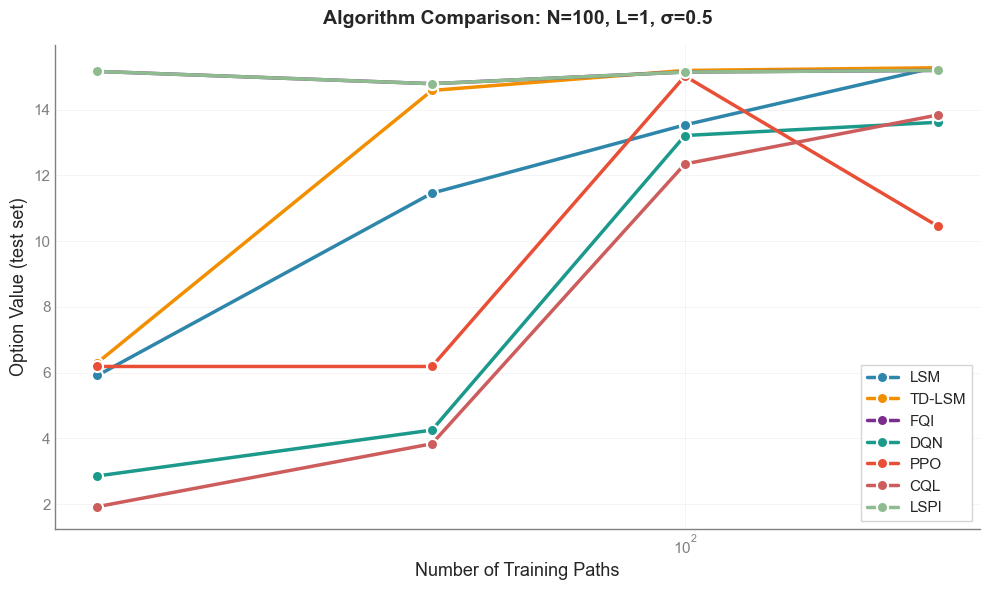

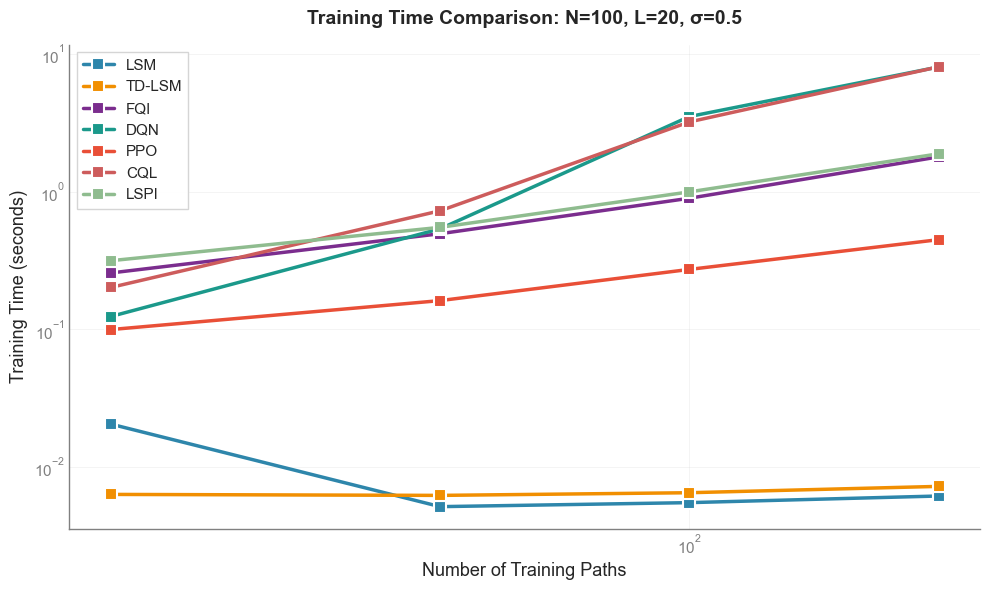


Configuration 2/2: N=300, L=2, delta=0, σ=0.7
n=  20  LSM=21.8027  TD-LSM=32.2158  DQN=6.6857  PPO=8.2473  FQI=43.7406  LSPI=43.7406  CQL=4.6247  [total:2.9s]
n=  50  LSM=29.2716  TD-LSM=42.2246  DQN=23.7957  PPO=23.3161  FQI=45.6280  LSPI=45.6280  CQL=16.1362  [total:9.9s]
n= 100  LSM=33.6959  TD-LSM=43.0611  DQN=34.7591  PPO=16.8304  FQI=45.6989  LSPI=45.6989  CQL=30.4075  [total:25.7s]
n= 200  LSM=34.8193  TD-LSM=43.4960  DQN=38.7029  PPO=10.0565  FQI=45.2372  LSPI=45.2372  CQL=35.8064  [total:65.3s]


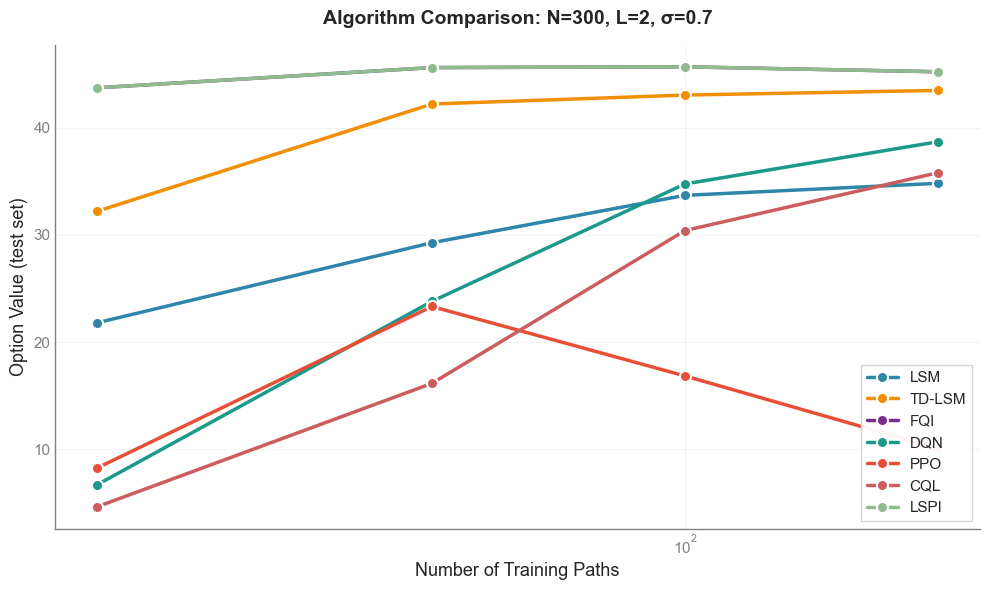

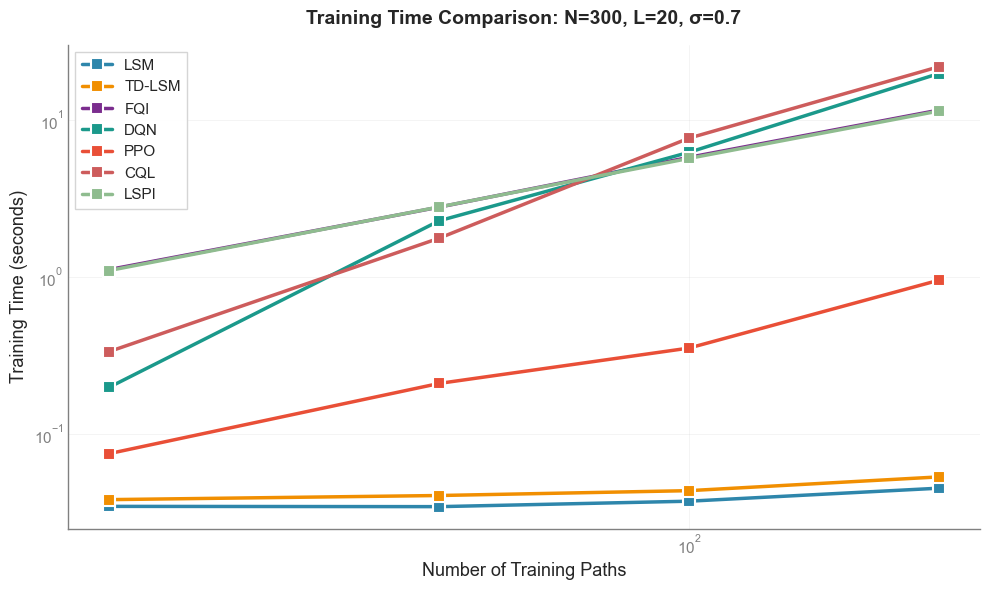

All configurations complete!


In [34]:
# ═══════════════════════════════════════════════════════════════════════════════
# Comparison: LSM vs TD-LSM vs DQN vs PPO vs FQI
# ═══════════════════════════════════════════════════════════════════════════════

# Define parameter configurations to test
param_configs = [
    {'N': 100, 'L': 1, 'delta': 0, 'sigma': 0.5},
    {'N': 300 , 'L': 2, 'delta': 0, 'sigma': 0.7},   # Use smaller N for speed!
    # {'N': 300, 'L': 5, 'delta': 0, 'sigma':0.7}
]

# SPEED SETTINGS - adjust these for faster runs
TEST_PATHS = 100      # Reduced from 10000 (5x speedup on evaluation)
train_sizes = [20, 50, 100, 200]  # Fewer sizes
n_repeats = 3       # Single run (no averaging) for speed

# Clean plot style
plt.style.use('seaborn-v0_8-whitegrid')

for config_idx, config in enumerate(param_configs):
    # Update params for this configuration
    test_params = Params(
        S0=params.S0, K=params.K, T=params.T, r=params.r,
        sigma=config.get('sigma', 0.5),
        N=config['N'], M=params.M, L=config['L'], 
        delta=config.get('delta', 0)
    )
    
    print(f"\n{'='*80}")
    print(f"Configuration {config_idx + 1}/{len(param_configs)}: N={test_params.N}, L={test_params.L}, delta={test_params.delta}, σ={test_params.sigma}")
    print(f"{'='*80}")
    
    # Generate test paths for this configuration
    test_paths_config = generate_paths(test_params, TEST_PATHS, seed=997)
    
    results = {algo: {'means': [], 'times': []} for algo in ['LSM', 'TD-LSM', 'FQI','DQN', 'PPO', 'CQL', 'LSPI']}
    
    for n in train_sizes:
        algo_vals = {algo: [] for algo in results.keys()}
        algo_times = {algo: [] for algo in results.keys()}
    
        for rep in range(n_repeats):
            seed = 42 + rep
            paths_n = generate_paths(test_params, n, seed=seed)
            
            # Train each algorithm separately to track individual times
            t0 = time.time()
            m_lsm = train_lsm(paths_n, test_params)
            algo_times['LSM'].append(time.time() - t0)
            
            t0 = time.time()
            m_td = train_td_lsm(paths_n, test_params)
            algo_times['TD-LSM'].append(time.time() - t0)
            
            t0 = time.time()
            m_dqn = train_dqn(paths_n, test_params, n_epochs=5)
            algo_times['DQN'].append(time.time() - t0)
            
            t0 = time.time()
            m_ppo = train_ppo(paths_n, test_params, n_epochs=5)
            algo_times['PPO'].append(time.time() - t0)
            
            t0 = time.time()
            m_fqi = train_fqi(paths_n, test_params, n_iterations=3)
            algo_times['FQI'].append(time.time() - t0)
            t0 = time.time()
            m_cql = ConservativeQLearning(state_dim=test_params.M + 2, hidden_dim=64, alpha=1.0)
            m_cql.train(paths_n, test_params, n_epochs=5)
            algo_times['CQL'].append(time.time() - t0)
            
            t0 = time.time()
            m_lspi = LeastSquarePolicyIteration(degree=3)
            m_lspi.train(paths_n, test_params, n_iterations=3)
            algo_times['LSPI'].append(time.time() - t0)

            
            # Evaluate all on same test set
            val_lsm, _ = evaluate_policy(m_lsm, test_paths_config, test_params)
            val_td, _ = evaluate_policy(m_td, test_paths_config, test_params)
            val_dqn, _ = evaluate_dqn(m_dqn, test_paths_config, test_params)
            val_ppo, _ = evaluate_ppo(m_ppo, test_paths_config, test_params)
            val_fqi, _ = evaluate_fqi(m_fqi, test_paths_config, test_params)
            
            algo_vals['LSM'].append(val_lsm)
            algo_vals['TD-LSM'].append(val_td)
            algo_vals['DQN'].append(val_dqn)
            algo_vals['PPO'].append(val_ppo)
            algo_vals['FQI'].append(val_fqi)
            val_cql, _ = evaluate_cql(m_cql, test_paths_config, test_params)
            val_lspi, _ = evaluate_lspi(m_lspi, test_paths_config, test_params)
            algo_vals['CQL'].append(val_cql)
            algo_vals['LSPI'].append(val_lspi)

        
        # Store results
        for algo in results.keys():
            results[algo]['means'].append(np.mean(algo_vals[algo]))
            results[algo]['times'].append(np.mean(algo_times[algo]))
        
        total_time = sum(np.mean(algo_times[a]) for a in results.keys())
        print(f"n={n:>4d}  LSM={np.mean(algo_vals['LSM']):.4f}  "
              f"TD-LSM={np.mean(algo_vals['TD-LSM']):.4f}  "
              f"DQN={np.mean(algo_vals['DQN']):.4f}  "
              f"PPO={np.mean(algo_vals['PPO']):.4f}  "
              f"FQI={np.mean(algo_vals['FQI']):.4f}  "
              f"LSPI={np.mean(algo_vals['LSPI']):.4f}  "
              f"CQL={np.mean(algo_vals['CQL']):.4f}  "
              f"[total:{total_time:.1f}s]")
    
    # ── Clean Plot ──
    fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')
    
    # Professional color palette
    colors = {
        'LSM': '#2E86AB',      # Steel blue
        'TD-LSM': '#F18F01',
        'DQN': '#1B998B',      # Teal
        'PPO': '#E94F37',
        'FQI': '#7B2D8E',       # Purple,
        'CQL': '#CD5C5C',
        'LSPI': '#8FBC8F'
    }
    
    for algo in results.keys():
        means = np.array(results[algo]['means'])
        ax.plot(train_sizes, means, 
                marker='o', 
                color=colors[algo],
                label=algo, 
                linewidth=2.5, 
                markersize=8,
                markeredgecolor='white',
                markeredgewidth=1.5)
    
    ax.set_xlabel('Number of Training Paths', fontsize=13, fontweight='medium')
    ax.set_ylabel('Option Value (test set)', fontsize=13, fontweight='medium')
    ax.set_title(f'Algorithm Comparison: N={test_params.N}, L={test_params.L}, σ={test_params.sigma}', 
                 fontsize=14, fontweight='bold', pad=15)
    ax.set_xscale('log')
    
    # Clean legend
    ax.legend(fontsize=11, loc='lower right', frameon=True, 
              fancybox=False, edgecolor='lightgray', framealpha=0.95)
    
    # Refined grid
    ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('gray')
    ax.spines['bottom'].set_color('gray')
    ax.tick_params(colors='gray', labelsize=11)
    
    plt.tight_layout()
    plt.show()
    
    # ── Training Time Plot ──
    fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')
    
    for algo in results.keys():
        times = np.array(results[algo]['times'])
        ax.plot(train_sizes, times, 
                marker='s', 
                color=colors[algo],
                label=algo, 
                linewidth=2.5, 
                markersize=8,
                markeredgecolor='white',
                markeredgewidth=1.5)
    
    ax.set_xlabel('Number of Training Paths', fontsize=13, fontweight='medium')
    ax.set_ylabel('Training Time (seconds)', fontsize=13, fontweight='medium')
    ax.set_title(f'Training Time Comparison: N={test_params.N}, L=20, σ={test_params.sigma}', 
                 fontsize=14, fontweight='bold', pad=15)
    ax.set_xscale('log')
    ax.set_yscale('log')
    
    ax.legend(fontsize=11, loc='upper left', frameon=True, 
              fancybox=False, edgecolor='lightgray', framealpha=0.95)
    
    ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('gray')
    ax.spines['bottom'].set_color('gray')
    ax.tick_params(colors='gray', labelsize=11)
    
    plt.tight_layout()
    plt.show()

print("All configurations complete!")
print("="*80)

In [35]:

class visualizer:
    def __init__(self, env, agent, optimal_policy=None):
        self.env = env
        self.agent = agent
        self.optimal_policy = env.solve_optimal_policy()[1] if optimal_policy is None else optimal_policy
    
    def plot_visit_counts(self):
        offer_visit_counts = (self.agent.visit_counts.sum(axis=(1,2)))
        plt.bar(range(len(offer_visit_counts)), offer_visit_counts)
        plt.xlabel('Offer Value Index')
        plt.ylabel('Number of Visits')
        plt.title('State Visit Counts by Offer Value (Sanity check)')
        plt.show()
    
    def plot_episode_rewards(self, rolling_window=100):
        rewards = self.agent.episode_rewards
        # rolling average over 100 episodes
        rewards = np.convolve(rewards, np.ones(rolling_window)/rolling_window, mode='valid')
        plt.plot(rewards)
        plt.xlabel('Episode')
        plt.ylabel('Total Reward')
        plt.title('Episode Rewards over Time')
        plt.show()

    def visualise_Q_table(self):
        Q = self.agent.Q  # shape: (T+1, S, 2, 2)

        # Remove terminal time step
        Q_view = Q[:-1, :, :, :]  # (T, S, z_idx, action)
        # Ensure time axis corresponds to time elapsed (left->right)
        Q_view = np.flip(Q_view, axis=0)

        vmin = np.min(Q_view)
        vmax = np.max(Q_view)

        T = Q_view.shape[0]
        time_ticks = np.arange(0, T, max(1, T // 5))
        time_labels = time_ticks

        fig, axs = plt.subplots(2, 2, figsize=(12, 10))

        # z = 1 (second stop left)
        axs[0, 0].imshow(Q_view[:, :, 0, 0].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[0, 0].set_title("Q(z=1): Continue")

        axs[0, 1].imshow(Q_view[:, :, 0, 1].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[0, 1].set_title("Q(z=1): Stop")

        # z = 2 (first stop left)
        axs[1, 0].imshow(Q_view[:, :, 1, 0].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[1, 0].set_title("Q(z=2): Continue")

        axs[1, 1].imshow(Q_view[:, :, 1, 1].T, vmin=vmin, vmax=vmax, origin='lower', aspect='auto')
        axs[1, 1].set_title("Q(z=2): Stop")

        for ax in axs.flat:
            ax.set_xlabel("Time")
            ax.set_ylabel("State")
            ax.set_xticks(time_ticks)
            ax.set_xticklabels(time_labels)

        plt.tight_layout()
        plt.show()


    def visualise_policy(self):
        """
        Visualize the learned double-sell policy.
        stop=1 means 'sell', stop=0 means 'continue'
        """
        policy = self.agent.get_policy()  # (state, time, stops)

        # Align dimensions
        policy = policy[:, :-1, :]  # remove terminal time
        # Reverse only the time axis so time increases left->right
        policy = np.flip(policy, axis=1)
        S, T, _ = policy.shape

        time_ticks = np.arange(0, T, max(1, T // 5))
        time_labels = time_ticks

        fig, axs = plt.subplots(1, 2, figsize=(14, 5))

        # -------- First Sell (z = 2) --------
        first_sell_policy = policy[:, :, 2]

        im1 = axs[0].imshow(
            first_sell_policy,
            cmap="RdYlGn",
            vmin=0,
            vmax=1,
            aspect="auto",
            origin="lower"
        )
        axs[0].set_title("First Sell Policy", fontsize=13, fontweight="bold")
        axs[0].set_xlabel("Time")
        axs[0].set_ylabel("State")
        axs[0].set_xticks(time_ticks)
        axs[0].set_xticklabels(time_labels)

        cbar1 = plt.colorbar(im1, ax=axs[0])
        cbar1.set_ticks([0, 1])
        cbar1.set_ticklabels(["Continue", "Sell"])

        # -------- Second Sell (z = 1) --------
        second_sell_policy = policy[:, :, 1]

        im2 = axs[1].imshow(
            second_sell_policy,
            cmap="RdYlGn",
            vmin=0,
            vmax=1,
            aspect="auto",
            origin="lower"
        )
        axs[1].set_title("Second Sell Policy", fontsize=13, fontweight="bold")
        axs[1].set_xlabel("Time")
        axs[1].set_ylabel("State")
        axs[1].set_xticks(time_ticks)
        axs[1].set_xticklabels(time_labels)

        cbar2 = plt.colorbar(im2, ax=axs[1])
        cbar2.set_ticks([0, 1])
        cbar2.set_ticklabels(["Continue", "Sell"])

        plt.tight_layout()
        plt.show()

        # ---- Statistics ----
        print("\nDouble-Sell Policy Statistics:")
        print(f" First sell rate: {first_sell_policy.mean():.2%}")
        print(f" Second sell rate: {second_sell_policy.mean():.2%}")
        
    def compare_with_optimal(self):
        """
        Compare Q-learning policy with optimal DP policy
        for a double-sell stopping problem.
        
        FIX: Corrected time axis orientation for proper visualization
        """

        if self.optimal_policy is None:
            print("⚠ Optimal policy not provided.")
            return

        # -------- Get policies --------
        q_policy = self.agent.get_policy()        # (S, T, 3)
        opt_policy = self.optimal_policy          # (S, T, 3)

        # -------- FIX: Reverse time axis for optimal policy --------
        # The optimal policy from solve_optimal_policy is indexed as [state, time_left, stops]
        # We need to flip it to match q_policy which is [state, time_elapsed, stops]
        opt_policy_flipped = np.flip(opt_policy, axis=1)

        # -------- Explicit time alignment --------
        T = min(q_policy.shape[1], opt_policy_flipped.shape[1])

        q_policy_view = q_policy[:, :T, :]
        opt_policy_view = opt_policy_flipped[:, :T, :]

        # -------- HARD SAFETY CHECK --------
        if q_policy_view.shape != opt_policy_view.shape:
            raise ValueError(
                f"Policy shape mismatch after alignment:\n"
                f"Q-policy: {q_policy_view.shape}\n"
                f"OPT-policy: {opt_policy_view.shape}"
            )

        # -------- First sell (z = 2) --------
        q_first = q_policy_view[:, :, 2]
        opt_first = opt_policy_view[:, :, 2]

        diff_first_sell = (q_first != opt_first).astype(float)

        # -------- Second sell (z = 1) --------
        q_second = q_policy_view[:, :, 1]
        opt_second = opt_policy_view[:, :, 1]

        diff_second_sell = (q_second != opt_second).astype(float)

        # -------- Plot --------
        fig, axs = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle("Policy Comparison: Q-Learning vs Optimal (Double Sell)", fontsize=16)

        # First sell
        im1 = axs[0, 0].imshow(q_first, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[0, 0].set_title("Q-Learning: First Sell")
        axs[0, 0].set_xlabel("Time Elapsed")
        axs[0, 0].set_ylabel("State")
        plt.colorbar(im1, ax=axs[0, 0])

        im2 = axs[0, 1].imshow(opt_first, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[0, 1].set_title("Optimal: First Sell")
        axs[0, 1].set_xlabel("Time Elapsed")
        axs[0, 1].set_ylabel("State")
        plt.colorbar(im2, ax=axs[0, 1])

        im3 = axs[0, 2].imshow(diff_first_sell, cmap="Reds", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[0, 2].set_title(f"Mismatch (First Sell): {diff_first_sell.mean():.1%}")
        axs[0, 2].set_xlabel("Time Elapsed")
        axs[0, 2].set_ylabel("State")
        plt.colorbar(im3, ax=axs[0, 2])

        # Second sell
        im4 = axs[1, 0].imshow(q_second, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[1, 0].set_title("Q-Learning: Second Sell")
        axs[1, 0].set_xlabel("Time Elapsed")
        axs[1, 0].set_ylabel("State")
        plt.colorbar(im4, ax=axs[1, 0])

        im5 = axs[1, 1].imshow(opt_second, cmap="RdYlGn", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[1, 1].set_title("Optimal: Second Sell")
        axs[1, 1].set_xlabel("Time Elapsed")
        axs[1, 1].set_ylabel("State")
        plt.colorbar(im5, ax=axs[1, 1])

        im6 = axs[1, 2].imshow(diff_second_sell, cmap="Reds", vmin=0, vmax=1, origin="lower", aspect="auto")
        axs[1, 2].set_title(f"Mismatch (Second Sell): {diff_second_sell.mean():.1%}")
        axs[1, 2].set_xlabel("Time Elapsed")
        axs[1, 2].set_ylabel("State")
        plt.colorbar(im6, ax=axs[1, 2])

        plt.tight_layout()
        plt.show()

        # -------- Stats --------
        print("\nPolicy Agreement Statistics (Double Sell)")
        print(f"First Sell Agreement: {(1 - diff_first_sell.mean()):.1%}")
        print(f"Second Sell Agreement: {(1 - diff_second_sell.mean()):.1%}")


In [40]:
def _get_continuous_action(algo_name, model, price_arr, t, rights, params, device=None):
    """Helper to query the action for a specific algorithm at a continuous state."""
    pay = payoff_put(price_arr.reshape(1, -1), params.K).item()
    
    # Auto-exercise logic at maturity or if no rights
    if rights <= 0: return 0
    if t >= params.N: return 1 if pay > 0 else 0

    if algo_name in ['LSM', 'TD-LSM', 'Optimal_LSM']:
        key = (rights, t)
        if key in model:
            # FIX: Dynamically infer the polynomial degree from the coefficient array length!
            # Array length = degree * M + 1  -->  degree = (length - 1) // M
            inferred_degree = (len(model[key]) - 1) // params.M
            
            X = poly_basis(price_arr.reshape(1, -1), params.K, degree=inferred_degree)[0]
            cont_est = float(X @ model[key])
            t_resume = min(t + params.delta + 1, params.N)
            future_val = query_V(model, price_arr, rights - 1, t_resume, params, degree=inferred_degree)
            ex_val = pay + (params.df ** (t_resume - t)) * future_val
            return 1 if ex_val > cont_est else 0
        else:
            return 1 if pay > 0 else 0 # Default if model doesn't exist for this step
            
    elif algo_name == 'DQN':
        model.eval()
        state = torch.tensor(make_state(price_arr, t, rights, params), device=device)
        with torch.no_grad():
            return model(state).argmax().item()
            
    elif algo_name == 'PPO':
        model.eval()
        state = torch.tensor(make_state(price_arr, t, rights, params), device=device)
        with torch.no_grad():
            logits, _ = model(state)
            return logits.argmax().item()
            
    elif algo_name == 'FQI':
        state = make_state(price_arr, t, rights, params)
        
        # FQI state length is M + 2 (prices + time + rights). 
        # features length = degree * (M + 2) + 1
        inferred_fqi_degree = (len(model[0]) - 1) // len(state)
        
        features = fqi_state_features(state, degree=inferred_fqi_degree)
        q0 = features @ model[0]
        q1 = features @ model[1]
        return 1 if q1 > q0 else 0
        
    return 0
def visualize_continuous_policies(models_dict, params, price_range=(50, 150), price_steps=100):
    """
    Plots the policy heatmaps (Time vs. Price) for continuous-state agents.
    Assumes M=1 (standard 1D price process) for 2D visualization.
    """
    if params.M > 1:
        print("Visualization is only supported for M=1 (single asset) in 2D.")
        return

    prices = np.linspace(price_range[0], price_range[1], price_steps)
    times = np.arange(1, params.N + 1)
    
    # We will plot for L=2 (First Sell) and L=1 (Second Sell)
    # Ensure we only plot rights that actually exist in the parameters
    rights_to_plot = [r for r in [2, 1] if r <= params.L]
    if not rights_to_plot:
         rights_to_plot = [params.L]
    
    for algo_name, model in models_dict.items():
        print(f"Generating policy heatmap for {algo_name}...")
        
        # Handle dynamic sizing based on number of rights plotted
        fig, axs = plt.subplots(1, len(rights_to_plot), figsize=(7 * len(rights_to_plot), 5))
        if len(rights_to_plot) == 1:
            axs = [axs]
            
        fig.suptitle(f"Learned Policy: {algo_name}", fontsize=16, fontweight='bold')
        
        for idx, rights in enumerate(rights_to_plot):
            policy_grid = np.zeros((len(prices), len(times)))
            
            for i, p_val in enumerate(prices):
                for j, t in enumerate(times):
                    price_arr = np.array([p_val])
                    
                    if algo_name in ['LSM', 'TD-LSM']:
                        pay = payoff_put(price_arr.reshape(1, -1), params.K).item()
                        if t == params.N:
                            action = 1 if pay > 0 else 0
                        else:
                            key = (rights, t)
                            if key in model:
                                inferred_deg = (len(model[key]) - 1) // params.M
                                X = poly_basis(price_arr.reshape(1, -1), params.K, degree=inferred_deg)[0]
                                cont_est = float(X @ model[key])
                                
                                t_resume = min(t + params.delta + 1, params.N)
                                future_val = query_V(model, price_arr, rights - 1, t_resume, params, degree=inferred_deg)
                                ex_val = pay + (params.df ** (t_resume - t)) * future_val
                                
                                action = 1 if ex_val > cont_est else 0
                            else:
                                action = 1 if pay > 0 else 0 
                                
                    elif algo_name == 'DQN':
                        model.eval()
                        state = torch.tensor(make_state(price_arr, t, rights, params), device=device)
                        with torch.no_grad():
                            action = model(state).argmax().item()
                            
                    elif algo_name == 'PPO':
                        model.eval()
                        state = torch.tensor(make_state(price_arr, t, rights, params), device=device)
                        with torch.no_grad():
                            logits, _ = model(state)
                            action = logits.argmax().item()
                            
                    elif algo_name == 'FQI':
                        state = make_state(price_arr, t, rights, params)
                        # FIXED: Explicitly look up by rights_left first
                        if rights in model:
                            inferred_fqi_degree = (len(model[rights][0]) - 1) // len(state)
                            features = fqi_state_features(state, degree=inferred_fqi_degree)
                            q0 = features @ model[rights][0]
                            q1 = features @ model[rights][1]
                            action = 1 if q1 > q0 else 0
                        else:
                            action = 0
                            
                    elif algo_name == 'LSPI':
                        # FIXED: Use the new predict method signature
                        state = make_state(price_arr, t, rights, params)
                        action = model.predict(state, rights)

                    policy_grid[i, j] = action

            # Plotting the grid
            im = axs[idx].imshow(
                policy_grid, 
                cmap="RdYlGn", 
                vmin=0, vmax=1, 
                aspect="auto", 
                origin="lower",
                extent=[1, params.N, price_range[0], price_range[1]]
            )
            
            title = f"Sell with {rights} right(s) left (z={rights})"
            axs[idx].set_title(title, fontsize=13)
            axs[idx].set_xlabel("Time Step (t)")
            axs[idx].set_ylabel("Asset Price (S)")
            
            cbar = plt.colorbar(im, ax=axs[idx])
            cbar.set_ticks([0, 1])
            cbar.set_ticklabels(["Hold", "Sell"])

        plt.tight_layout()
        plt.show()

In [41]:
# # 1. Train your "Gold Standard" benchmark optimal policy (lots of paths)
# print("Training Gold Standard benchmark...")
# benchmark_paths = generate_paths(test_params, 50000, seed=123) # Big dataset
# optimal_lsm_model = train_lsm(benchmark_paths, test_params, degree=4)

# # 2. Compare your fast/smaller models against the benchmark
# print("Comparing PPO against Benchmark LSM...")
# compare_continuous_with_optimal(
#     current_algo_name='PPO', 
#     current_model=m_ppo,       # Your trained PPO model
#     optimal_algo_name='Optimal_LSM', 
#     optimal_model=optimal_lsm_model, 
#     params=test_params
# )

# print("Comparing DQN against Benchmark LSM...")
# compare_continuous_with_optimal(
#     current_algo_name='DQN', 
#     current_model=m_dqn, 
#     optimal_algo_name='Optimal_LSM', 
#     optimal_model=optimal_lsm_model, 
#     params=test_params
# )

In [42]:
# ── Pointwise V query (Updated) ──
def query_V(models, prices_1d, l, t, params, degree=None):
    """Return V(l, t) for a SINGLE state. Dynamically infers polynomial degree if not provided."""
    if l == 0 or t > params.N:
        return 0.0
    p = payoff_put(prices_1d.reshape(1, -1), params.K).item()
    if t == params.N:
        return p
        
    key = (l, t)
    if key in models:
        # Dynamically infer degree: length = degree * M + 1
        inferred_deg = (len(models[key]) - 1) // params.M if degree is None else degree
        x = poly_basis(prices_1d.reshape(1, -1), params.K, inferred_deg)[0]
        cont_est = float(x @ models[key])
    else:
        cont_est = 0.0
    return max(p, cont_est)


# ── Batch V query (Updated) ──
def query_V_batch(models, prices, l, t, params, degree=None):
    """Vectorized V query. Dynamically infers polynomial degree if not provided."""
    prices_2d = prices[:, t]
    n = len(prices_2d)
    if l == 0 or t > params.N:
        return np.zeros(n)
    p = payoff_put(prices_2d, params.K)
    if t == params.N:
        return p
        
    time_left = params.N - t + 1
    if l > time_left // (params.delta + 1):
        for future_t in range(t, params.N + 1):
            p += payoff_put(prices[:, future_t], params.K) * params.df**(future_t - t)
        return p

    key = (l, t)
    if key in models:
        # Dynamically infer degree: length = degree * M + 1
        inferred_deg = (len(models[key]) - 1) // params.M if degree is None else degree
        X = poly_basis(prices_2d, params.K, inferred_deg)
        cont_est = X @ models[key]
    else:
        cont_est = np.zeros(n)
    return np.maximum(p, cont_est)


# ── Evaluate Policy (Updated) ──
def evaluate_policy(models, paths, params, degree=None):
    """Evaluate LSM / TD-LSM policy. Dynamically infers polynomial degree if not provided."""
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    payoffs_all = np.array([payoff_put(paths[:, t], K) for t in range(N + 1)]).T
    
    rewards = np.zeros(n_paths)
    
    for i in range(n_paths):
        rights_left = L
        t = 1
        total_reward = 0.0
        
        while t <= N and rights_left > 0:
            p_t = payoffs_all[i, t]
            
            if t == N:
                if p_t > 0:
                    total_reward += p_t * (df ** t)
                    rights_left -= 1
                break
            
            if p_t <= 0:
                t += 1
                continue
            
            key = (rights_left, t)
            if key in models:
                # Dynamically infer degree: length = degree * M + 1
                inferred_deg = (len(models[key]) - 1) // params.M if degree is None else degree
                x = poly_basis(paths[i, t].reshape(1, -1), K, inferred_deg)[0]
                cont_est = float(x @ models[key])
            else:
                cont_est = 0.0
            
            t_resume = min(t + delta + 1, N)
            future_val = query_V(models, paths[i, t_resume], rights_left - 1, t_resume, params, degree)
            ex_val = p_t + (df ** (t_resume - t)) * future_val
            
            if ex_val > cont_est:
                total_reward += p_t * (df ** t)
                rights_left -= 1
                t = t_resume
            else:
                t += 1
        
        rewards[i] = total_reward
    
    return rewards.mean(), rewards


# ── Evaluate FQI (Updated) ──
def evaluate_fqi(Q_coeffs, paths, params, degree=None):
    """Evaluate FQI policy. Dynamically infers polynomial degree if not provided."""
    N, df, K, L, delta = params.N, params.df, params.K, params.L, params.delta
    n_paths = len(paths)
    rewards = np.zeros(n_paths)
    
    for i in range(n_paths):
        path = paths[i]
        t = 1
        rights_left = L
        cooldown = 0
        total_reward = 0.0
        
        while t <= N and rights_left > 0:
            state = make_state(path[t], t, rights_left, params)
            
            # Dynamically infer FQI degree: length = degree * state_dim + 1
            inferred_deg = (len(Q_coeffs[0]) - 1) // len(state) if degree is None else degree
            features = fqi_state_features(state, inferred_deg)
            
            q0 = features @ Q_coeffs[0]
            q1 = features @ Q_coeffs[1]
            action = 1 if q1 > q0 else 0
            
            if cooldown > 0:
                action = 0
                cooldown -= 1
            
            if action == 1 and rights_left > 0:
                pay = payoff_put(path[t].reshape(1, -1), K).item()
                total_reward += pay * (df ** t)
                rights_left -= 1
                cooldown = delta
            
            t += 1
        
        if rights_left > 0:
            pay = payoff_put(path[N].reshape(1, -1), K).item()
            if pay > 0:
                total_reward += pay * (df ** N)
        
        rewards[i] = total_reward
    
    return rewards.mean(), rewards

Visualizing Agent Decision Boundaries...
Generating policy heatmap for LSM...


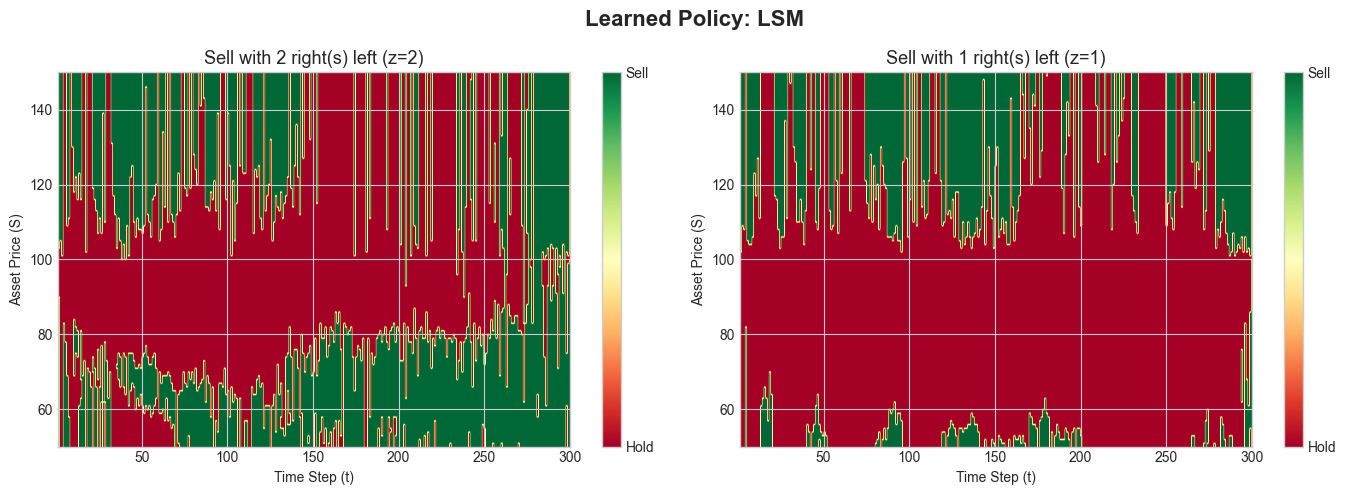

Generating policy heatmap for TD-LSM...


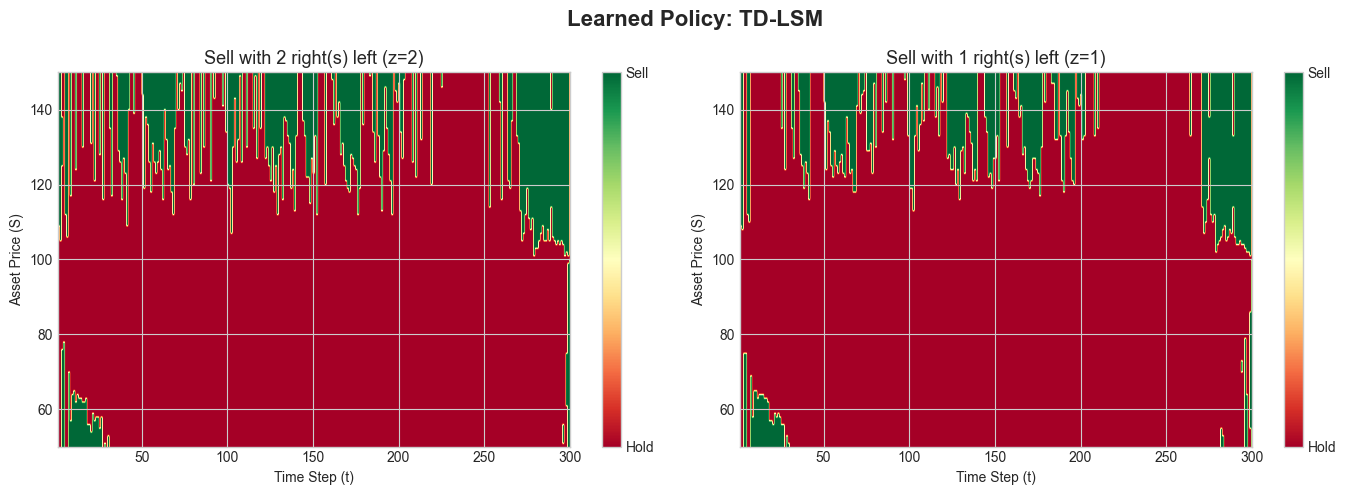

Generating policy heatmap for DQN...


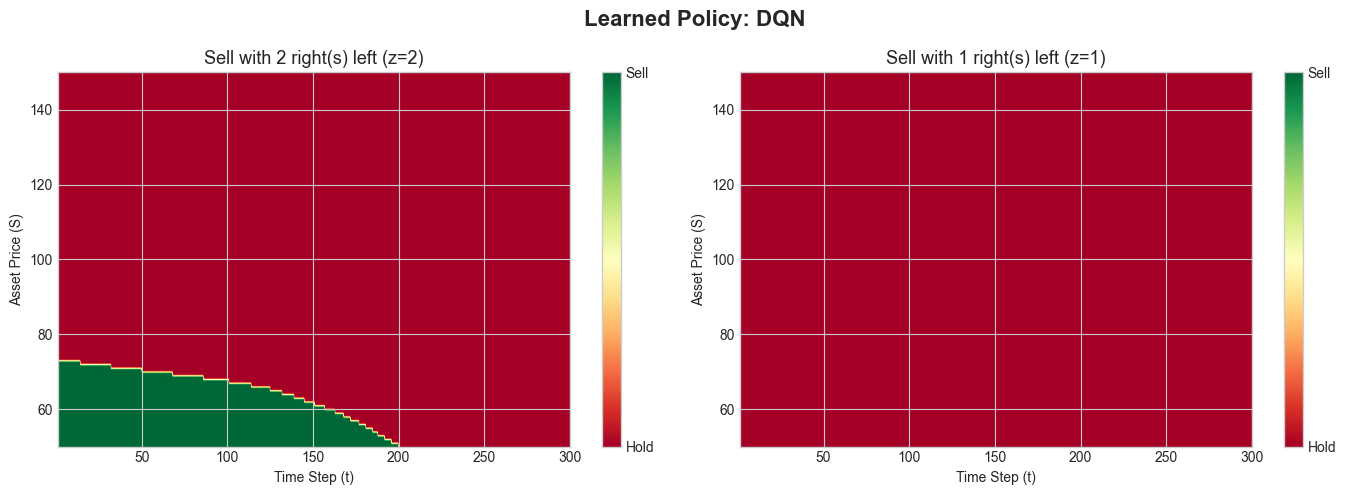

Generating policy heatmap for PPO...


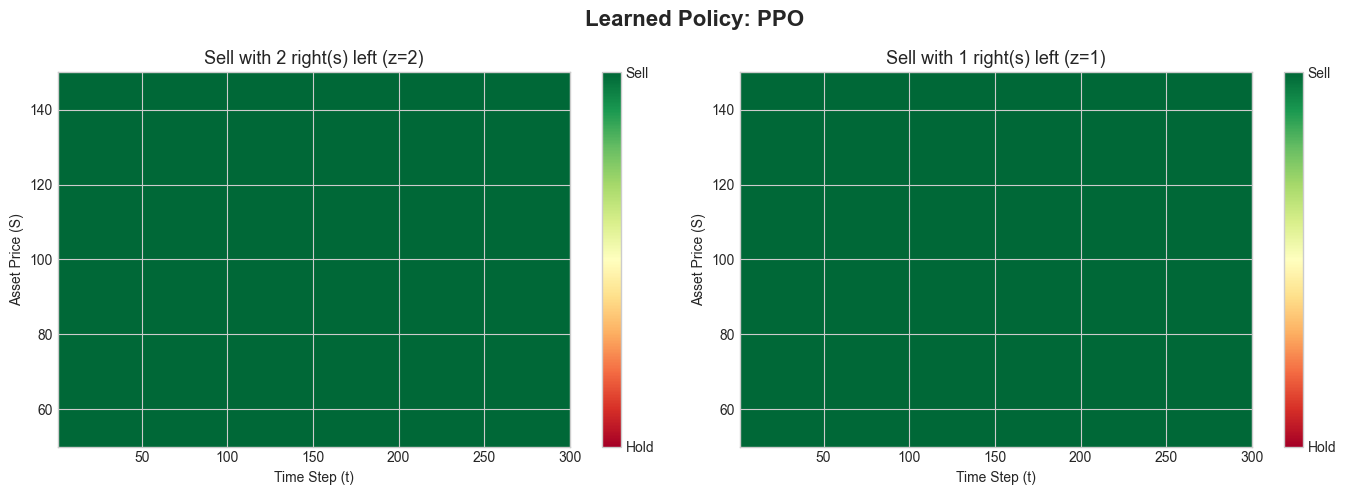

Generating policy heatmap for FQI...


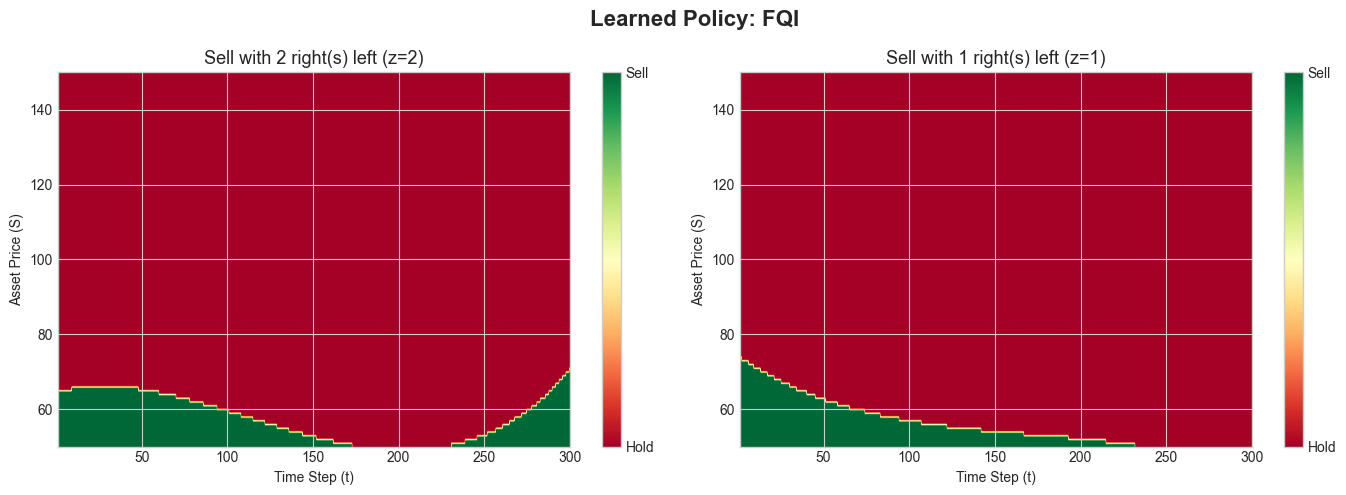

In [43]:
# Visualize learned policies for all agents
models_dict = {
    'LSM': m_lsm,
    'TD-LSM': m_td,
    'DQN': m_dqn,
    'PPO': m_ppo,
    'FQI': m_fqi
}

print('Visualizing Agent Decision Boundaries...')
visualize_continuous_policies(models_dict, test_params, price_range=(50, 150), price_steps=100)


Training CQL and LSPI for Decision Boundary Visualization...

Plotting Decision Boundary for CQL in a separate cell


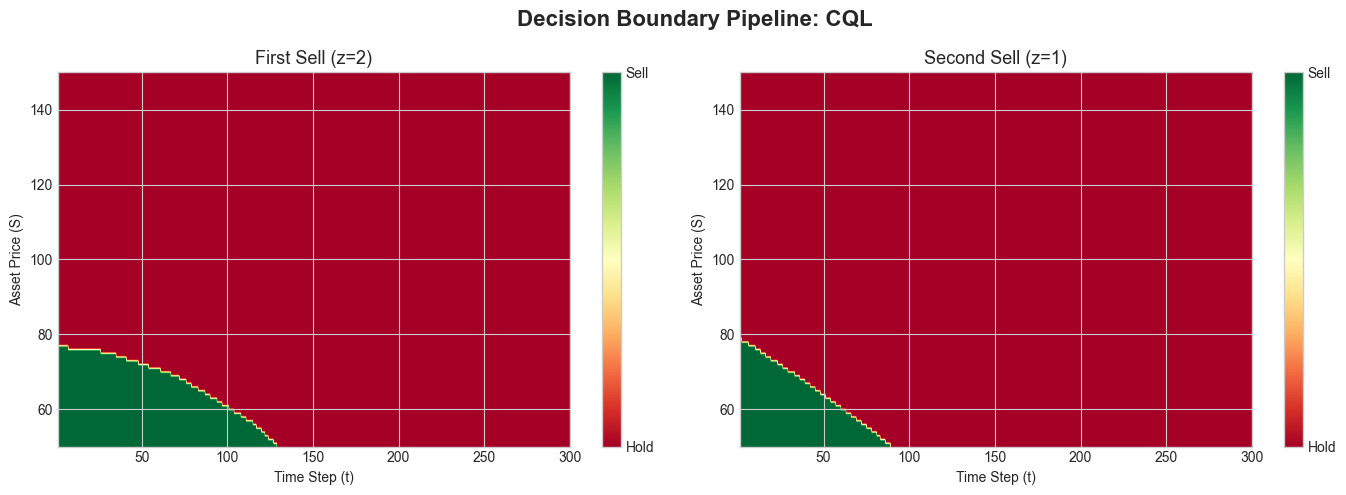

In [44]:
# Visualize Individual Policies for CQL and LSPI

# 1. Train CQL and LSPI visually
print("Training CQL and LSPI for Decision Boundary Visualization...")
benchmark_paths = generate_paths(test_params, 500, seed=42) # moderate size to prevent taking too long

cql_model = ConservativeQLearning(state_dim=test_params.M + 2, hidden_dim=64, alpha=1.0)
cql_model.train(benchmark_paths, test_params, n_epochs=5)

lspi_model = LeastSquarePolicyIteration(degree=3)
lspi_model.train(benchmark_paths, test_params, n_iterations=3)

# 2. Add them to dictionary specifically for custom handling if needed, or re-use existing function
cql_lspi_dict = {
    'CQL': cql_model,
    'LSPI': lspi_model
}

# Define a robust plotting function for these objects
def plot_agent_decision_boundary(algo_name, model, params, price_range=(50, 150), price_steps=100):
    prices = np.linspace(price_range[0], price_range[1], price_steps)
    times = np.arange(1, params.N + 1)
    rights_to_plot = [2, 1]
    
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"Decision Boundary Pipeline: {algo_name}", fontsize=16, fontweight='bold')
    
    for idx, rights in enumerate(rights_to_plot):
        policy_grid = np.zeros((len(prices), len(times)))
        for i, p_val in enumerate(prices):
            for j, t in enumerate(times):
                state = make_state(np.array([p_val]), t, rights, params)
                if algo_name == 'CQL':
                    action = model.predict(state)
                elif algo_name == 'LSPI':
                    action = model.predict(state)
                policy_grid[i, j] = action

        im = axs[idx].imshow(
            policy_grid, 
            cmap="RdYlGn", 
            vmin=0, vmax=1, 
            aspect="auto", 
            origin="lower",
            extent=[1, params.N, price_range[0], price_range[1]]
        )
        title = "First Sell (z=2)" if rights == 2 else "Second Sell (z=1)"
        axs[idx].set_title(title, fontsize=13)
        axs[idx].set_xlabel("Time Step (t)")
        axs[idx].set_ylabel("Asset Price (S)")
        cbar = plt.colorbar(im, ax=axs[idx])
        cbar.set_ticks([0, 1])
        cbar.set_ticklabels(["Hold", "Sell"])

    plt.tight_layout()
    plt.show()

print("\nPlotting Decision Boundary for CQL in a separate cell")
plot_agent_decision_boundary('CQL', cql_lspi_dict['CQL'], test_params)




Plotting Decision Boundary for LSPI in a separate cell


TypeError: LeastSquarePolicyIteration.predict() missing 1 required positional argument: 'rights_left'

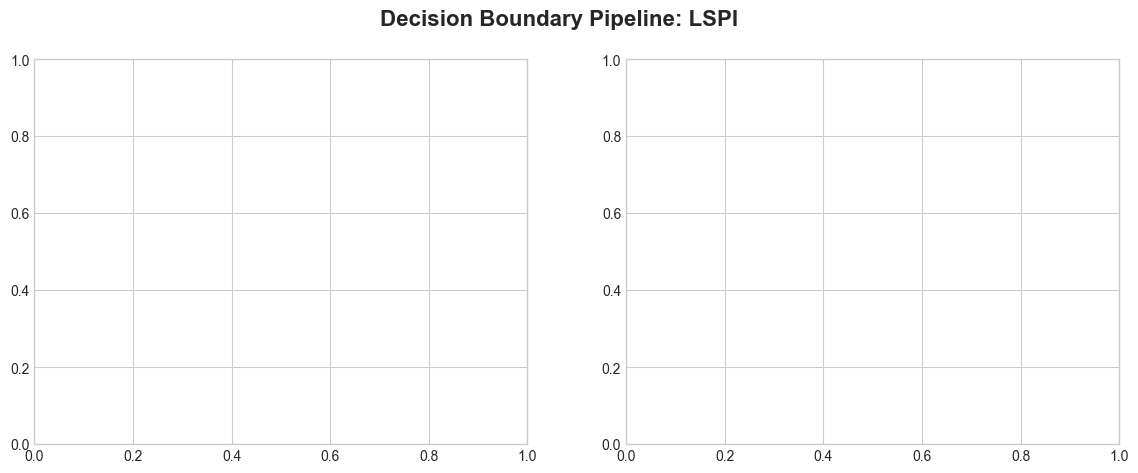

In [45]:
print("\nPlotting Decision Boundary for LSPI in a separate cell")
plot_agent_decision_boundary('LSPI', cql_lspi_dict['LSPI'], test_params)

